# Семинар 6. Эмбеддинги слов и классификация текстов

На занятии мы попробуем на практике то, что изучили на лекции - посмотрим на операции с эмбеддингами, попробуем самостоятельно обучить word2vec, а также решить с их помощью прикладную задачу классификации текстов. Кроме того, посмотрим на нейросетевой подход к решению данной задачи, а именно, как использовать MLP для обработки текстов.

Для загрузки предобученных эмбеддингов и датасета IMDb нужен доступ к сети. Обучающие ячейки можно запускать на GPU; на CPU уменьшите число эпох.

## Источники

- [Конспект по основам NLP](https://github.com/mmp-practicum-team/mmp_practicum_spring_2024/blob/main/Seminars/Seminar%2007/%D0%AF%D0%B7%D1%8B%D0%BA%D0%BE%D0%B2%D1%8B%D0%B5%20%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8.%20Torchtext.ipynb)

- [Документация gensim](https://radimrehurek.com/gensim/models/word2vec.html)

- **UMAP**: [Leland McInnes et al., 2018](https://arxiv.org/abs/1802.03426), примерно 22 тысячи цитирований

- [Документация umap](https://umap-learn.readthedocs.io/en/latest/)

- [Выделение смысловых компонент слов с помощью Lasso](https://lars76.github.io/2021/06/16/operations-contextual-embeddings.html)

- [Датасет рецензий с Imdb](https://ai.stanford.edu/~amaas/data/sentiment/).

- [Документация CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)

- [Примеры датасетов для классификации текстов](https://lena-voita.github.io/nlp_course/text_classification.html#dataset_examples)

- [Документация fasttext](https://fasttext.cc/docs/en/python-module.html)

- [Документация tokenizers](https://huggingface.co/docs/tokenizers/index)

- [Документация datasets](https://huggingface.co/docs/datasets/index)

- Для большинства изображений указан источник, откуда оно взято, как правило, являющийся статьей

## Подготовка окружения

In [1]:
#!pip install gensim
#!pip install catboost
#!pip install tokenizers

In [2]:
import os
import numpy as np
import random

import matplotlib_inline
import matplotlib.pyplot as plt

%matplotlib inline


np.random.seed(52)
random.seed(52)

## Модели эмбеддингов на основе предсказаний

Мы будем пользоваться библиотекой [gensim](https://radimrehurek.com/gensim/models/word2vec.html), так как в ней удобно реализованы различные методы обучения эмбеддингов: `word2vec`.

Кроме того, существуют уже предобученные модели, что позволяет в несколько строк получить качественные эмбеддинги. Посмотрим на список доступных моделей ниже.

Для наглядности мы будем использовать `word2vec-ruscorpora-300`, так как это обученные эмбеддинги для русского языка.

Можно заметить, что каждое слово имеет суффикс, который отвечает за часть речи (NOUN - существительное, VERB - глагол и тд). Задача определения части речи называется `part-of-speech tagging`.

Красивую визуализацию можно найти [тут](https://rusvectores.org/ru/visual/).

Мы же попробуем визуализировать и изучить интересные свойства самостоятельно.

## Операции над эмбеддингами

В моделях из библиотеки `gensim` реализован автоматический поиск наиболее похожих слов, то есть поиск слов, чьи эмбеддинги наиболее близки к эмбеддингу исходного.

Кроме того, мы можем производить над эмбеддингами арифметические операции.

Чуть аккуратней этот функционал уже реализован в библиотеке.

У некоторых слов много значений, поэтому мы можем найти достаточно разные слова по смыслу.

Кроме того, можно быстро находить синонимы.

Мы ожидаем, что для разных по смыслу слов расстояние между эмбеддингами будет больше, чем между похожими.

Однако не стоит забывать, что эмбеддинги не идеальные, поэтому иногда возникают странные ситуации.

В случае более хороших эмбеддингов, полученных из нейронных сетей, можно даже обучать линейные модели для поиска "смысловых компонент" слова. Подробнее можно изучить [по ссылке](https://lars76.github.io/2021/06/16/operations-contextual-embeddings.html).

## Классификация

Мы хотим использовать векторные представления слов для алгоритмов машинного обучения или нейронных сетей. Прежде чем перейти к нейронным сетям, нам нужны бейзлайны - то есть то, с чем будем сравниваться. Сначала проверим, как работают стандартные алгоритмы машинного обучения на эмбеддингах.

Мы будем решать задачу бинарной классификации для [датасета рецензий с Imdb](https://ai.stanford.edu/~amaas/data/sentiment/).

В качестве базовой модели будем использовать [CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier).

Подробный список классических датасетов для классификации текста можно посмотреть [здесь](https://lena-voita.github.io/nlp_course/text_classification.html#dataset_examples).

In [3]:
"""
if not os.path.exists("aclImdb"):
    if not os.path.exists("aclImdb_v1.tar.gz"):
        ! wget https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
    ! tar -xf aclImdb_v1.tar.gz
"""

'\nif not os.path.exists("aclImdb"):\n    if not os.path.exists("aclImdb_v1.tar.gz"):\n        ! wget https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz\n    ! tar -xf aclImdb_v1.tar.gz\n'

Мы не будем усердно заниматься предобработкой, так как наша цель - именно сравнить методы, а не добиться более высокого качества. В качестве предобработки мы приведем все символы к нижнему регистру.

In [ ]:
#!pip3 install openpyxl
import pandas as pd
def preprocess(l):
    return l.lower()

filename='markup_21_10_2026_priv.xlsx'
df = pd.read_excel(filename)

In [ ]:
def get_dataset(split='train', df=None, 
                date_train_start = '2025-03-10',
                date_train_end = '2026-10-13',
                date_val_start = '2026-10-14',
                date_val_end = '2026-10-18',
                date_test_start = '2026-10-19', 
                date_test_end = '2026-12-10'):
    #read_excel
    local_df = df.copy()
    if split == 'train':
        local_df = local_df[local_df['record_date'] >= date_train_start]
        local_df = local_df[local_df['record_date'] <= date_train_end]
        df_trues = local_df[local_df['is_fraud'] == 1]
        df_falses = local_df[local_df['is_fraud'] == 0]
        #filter first 2000 trues
        df_trues = df_trues.sample(frac=1, random_state=42)[:20000]
        
        #filter first 20000 falses
        df_falses = df_falses.sample(frac=1, random_state=42)[:80000]
        
        #concat
        local_df = pd.concat([df_trues, df_falses])
    elif split == 'val':
        local_df = local_df[local_df['record_date'] >= date_val_start]
        local_df = local_df[local_df['record_date'] <= date_val_end]
    else:
        local_df = local_df[local_df['record_date'] >= date_test_start]
        local_df = local_df[local_df['record_date'] <= date_test_end]
    
    X = local_df['original_text'].values
    y = local_df['is_fraud'].values
    print(f"Объектов положительного класса {len(y[y == 1])}")
    print(f"Объектов отрицательного класса {len(y[y == 0])}")
    print(f"Соотношение классов {len(y[y == 1]) / len(y[y == 0])}")
    return X, y

In [ ]:
X_train, y_train = get_dataset(split='train',df=df)

Объектов положительного класса 20000
Объектов отрицательного класса 80000
Соотношение классов 0.25


In [ ]:
X_val, y_val = get_dataset(split='val',df=df)

Объектов положительного класса 190
Объектов отрицательного класса 2852
Соотношение классов 0.06661991584852735


In [ ]:
X_test, y_test = get_dataset(split='test',df=df)

Объектов положительного класса 102
Объектов отрицательного класса 1687
Соотношение классов 0.06046235921754594


Посмотрим на примеры предложений.

In [ ]:
X_train[0]

'Доброе утро. Юридическая компания, победа. Код вам отправила, для входа в Госуслуги назовете? Да, да, да, да, да, да. Угу. Угу, все, спасибо большое, зашла. Угу, все, всего доброго. '

In [ ]:
X_val[0]

'Здравствуйте. Вы, Мирошниченко Егора папа, да. И кто?  Ваш номер написано, поэтому это Центр гигиены, эпидемиологии, беспокоит. А кто будет. Кто? Ну, почему-то нам передали, ваш номер. Стоит, поэтому мы хотели уточнить, почему. У него в экстренном извещении. Поэтому только спрашиваю. Извините все. Тогда извините. '

In [ ]:
X_test[0]

'Алло, здравствуйте. Звоню вам по поводу работы, вы отклик? Оставили, вы еще в поиске? У нас ведет набор на службу по контракту на гражданские должности в Луганскую Донецкую республику рассматриваете? У нас ведется набор на службу по контракту на гражданские должности в Луганскую Донецкую республику. Да, то есть это охрана водитель, механик, сварщик, кладовщик, электрик, монтажник, слесарь. Потому что набор ведется в Луганскую Донецкую республику и набор ведет Министерство обороны. То есть это на восстановление. Да, это идет через Министерство обороны. То есть это идет на восстановление. '

Для обучения моделей эмбеддингов, нам нужно разделить слова на структурные единицы (символы, слова, n-граммы). Мы будем работать на уровне слов.

In [ ]:
#def get_corpus(X_data):
#
#    return list(x.split() for x in X_data)

import re
def get_corpus(X_data):
    corpus = []
    for x in X_data:
        # Заменяем всю пунктуацию на пустую строку
        text_clean = re.sub(r'[^\w\s]', '', x)
        # Разбиваем по пробелам
        corpus.append(text_clean.split())
    return corpus

In [ ]:
corpus_train = get_corpus(X_train)
corpus_val   = get_corpus(X_val)
corpus_test  = get_corpus(X_test)

In [ ]:
corpus_train[0][:10]

['Доброе',
 'утро',
 'Юридическая',
 'компания',
 'победа',
 'Код',
 'вам',
 'отправила',
 'для',
 'входа']

Обучим word2vec модель на наших данных.


In [ ]:
main_corpus = corpus_train

In [ ]:
from scipy.sparse import csr_matrix

def encode_corpus_one_hot(corpus, vocab_size):
    """
    Создает разреженную One-Hot (Bag of Words) матрицу для корпуса текстов.
    """
    rows = []
    cols = []
    data = []
    
    for text_idx, tokens in enumerate(corpus):
        # Получаем ID токенов для текущего текста с помощью вашего токенизатора
        # Устанавливаем is_pretokenized=True, так как corpus уже разбит на слова
        result = tokenizer.encode(tokens, is_pretokenized=True)
        token_ids = result.ids
        
        # Оставляем только уникальные токены в рамках одного текста (One-Hot признак наличия слова)
        unique_tokens = set(token_ids)
        
        for token_id in unique_tokens:
            rows.append(text_idx)
            cols.append(token_id)
            data.append(1.0) # 1 означает, что слово присутствует в тексте
            
    # Собираем эффективную разреженную матрицу (размер: число_текстов x размер_словаря)
    return csr_matrix((data, (rows, cols)), shape=(len(corpus), vocab_size), dtype=np.float32)

# Получаем размер словаря из вашего токенизатора (в ноутбуке это 30000)
vocab_size = tokenizer.get_vocab_size()

# Кодируем тренировочную, валидационную и тестовую выборки
print("Кодирование train...")
enc_train_ohe = encode_corpus_one_hot(corpus_train, vocab_size)

print("Кодирование val...")
enc_val_ohe = encode_corpus_one_hot(corpus_val, vocab_size)

print("Кодирование test...")
enc_test_ohe = encode_corpus_one_hot(corpus_test, vocab_size)

print(f"Размерность полученной OHE-матрицы для train: {enc_train_ohe.shape}")


In [ ]:
from catboost import CatBoostClassifier

In [ ]:
def accuracy(y_pred, y_test):
    acc = np.mean(y_pred == y_test)
    print(f"Правильность {acc:.3f}")

def precision(y_pred, y_test):
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)
    prec = np.mean(y_pred[y_pred == 1] == y_test[y_pred == 1])
    print(f"Точность {prec:.3f}")

def recall(y_pred, y_test):
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)
    rec = np.mean(y_pred[y_test == 1] == y_test[y_test == 1])
    print(f"Полнота {rec:.3f}")

In [ ]:
%%time
%%time
from catboost import CatBoostClassifier

# Инициализируем классификатор с балансировкой классов, как в вашем исходном коде
clf_ohe = CatBoostClassifier(random_seed=52, auto_class_weights='Balanced')

# Обучаем модель на разреженных One-Hot векторах
clf_ohe.fit(enc_train_ohe, y_train, verbose=100) # verbose=100, чтобы видеть прогресс


CPU times: user 1min 4s, sys: 9.38 s, total: 1min 14s
Wall time: 12.1 s


CatBoostClassifier(auto_class_weights='Balanced', random_seed=52)

In [ ]:
y_pred = clf_ohe.predict(enc_val_ohe)
accuracy(y_pred, y_val)
precision(y_pred, y_val)
recall(y_pred, y_val)

Правильность 0.821
Точность 0.219
Полнота 0.732


In [ ]:
y_pred = clf_ohe.predict(enc_test_ohe)
accuracy(y_pred, y_test)
precision(y_pred, y_test)
recall(y_pred, y_test)

Правильность 0.748
Точность 0.157
Полнота 0.784


## Нейронный подход

Мы рассмотрим, как токенизировать тексты с помощью библиотеки `tokenizers`, чтобы работа с токенами происходила независимо от архитектуры и обучения.

Важной частью будет сравнение результатов с подходами из классического машинного обучения.


In [ ]:
#!pip3 install torch
from tqdm import tqdm
from functools import partial


import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import tokenizers
from tokenizers import Tokenizer, trainers

os.environ["TOKENIZERS_PARALLELISM"] = "false"

In [ ]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def print_params_count(model):

    total_params = sum(p.numel() for p in model.parameters())
    total_params_grad = sum(p.numel() for p in model.parameters() if p.requires_grad)

    model_name = model.__class__.__name__
    print(f"Информация о числе параметров модели: {model_name}")
    print(f"Всего параметров: \t\t {total_params}")
    print(f"Всего обучаемых параметров: \t {total_params_grad}")
    print()

In [ ]:
set_global_seed(52)

### tokenizers

Прежде чем создавать модель, нам необходимо создать словарь и произвести токенизацию предложений. Именно от словаря будет зависеть, насколько много "слов" знает наша модель. Мы воспользуемся библиотекой [tokenizers](https://huggingface.co/docs/tokenizers/index). Библиотека `tokenizers` является частью инфраструктуры `Hugging Face`, с которой вы познакомитесь на ближайших парах.


Токенизация происходит через класс `tokenizer`. Для того чтобы получить `tokenizer` его надо сначала **обучить**, для этого нам необходимо использовать `tokenizers.trainers`. Так как мы будем работать на уровне слов, то выберем `tokenizers.trainers.WordLevelTrainer`.

Для работы с текстами нам необходимо зарезервировать два специальных токена:
1. `<pad>` для токена означающего паддинг
2. `<unk>` для токенов, которые отсутствуют в словаре

#### `WordLevelTrainer`

Будем рассматривать словарь размером 5000 слов.


```python
trainers.WordLevelTrainer(self, /, *args, **kwargs)
Docstring:     
Trainer capable of training a WorldLevel model

Args:
    vocab_size (:obj:`int`, `optional`):
        The size of the final vocabulary, including all tokens and alphabet.

    min_frequency (:obj:`int`, `optional`):
        The minimum frequency a pair should have in order to be merged.

    show_progress (:obj:`bool`, `optional`):
        Whether to show progress bars while training.

    special_tokens (:obj:`List[Union[str, AddedToken]]`):
        A list of special tokens the model should know of.
```

In [ ]:
top_n_words = 30_000#5_000

In [ ]:
trainer = trainers.WordLevelTrainer(
    vocab_size     = top_n_words,
    special_tokens = ["<pad>", "<unk>"],
    show_progress  = True
)

tokenizer = tokenizers.Tokenizer(
    model=tokenizers.models.WordLevel()
)

Мы будем обучаться из памяти, поэтому нам необходимо передать итератор, который пройдет по всем текстам, которые уже разбиты на слова.

In [ ]:
text_data = corpus_train
text_data[0][:10]

['Доброе',
 'утро',
 'Юридическая',
 'компания',
 'победа',
 'Код',
 'вам',
 'отправила',
 'для',
 'входа']

In [ ]:
tokenizer.train_from_iterator(tqdm(text_data, total=len(text_data)), trainer=trainer)

100%|██████████| 100000/100000 [00:06<00:00, 16445.47it/s]


Посмотрим на словарь.

In [ ]:
print(f"Размер словаря {tokenizer.get_vocab_size()}")

print(list(tokenizer.get_vocab().keys())[:10])

for idx in [0, 1, 2, 21, 42]:
    print(f"idx = {idx}, word = {tokenizer.id_to_token(idx)}")

Размер словаря 30000
['формы', 'собственности', 'захочешь', 'льготами', 'Ул', 'начислила', 'Лерочка', 'видеосвязи', 'занимается', 'Лия']
idx = 0, word = <pad>
idx = 1, word = <unk>
idx = 2, word = я
idx = 21, word = по
idx = 42, word = еще


**Важно:** Cпециальные токены имеют наименьшие *id* по умолчанию.

Для кодирования предложений используется метод `encode`, установим `is_pretokenized=True`.


In [ ]:
tokenized_text = text_data[0][:20]

print("Исходный текст:")
print(tokenized_text)

result = tokenizer.encode(tokenized_text, is_pretokenized=True)
print(result)

print("Tokens ids: ", result.ids)

Исходный текст:
['Доброе', 'утро', 'Юридическая', 'компания', 'победа', 'Код', 'вам', 'отправила', 'для', 'входа', 'в', 'Госуслуги', 'назовете', 'Да', 'да', 'да', 'да', 'да', 'да', 'Угу']
Encoding(num_tokens=20, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Tokens ids:  [466, 247, 8310, 174, 6151, 1146, 18, 925, 67, 1947, 4, 623, 6636, 8, 14, 14, 14, 14, 14, 27]


Для декодирования воспользуемся методом `decode`, мы хотим посмотреть насколько словарь из 5 тысяч слов выразительный, то есть какие слова мы пропускаем и понятен ли смысл предложения без них.

In [ ]:
print("Исходный текст:")
print(tokenized_text)

print("Результат декодирования:")
print(tokenizer.decode(result.ids, skip_special_tokens=False))

Исходный текст:
['Доброе', 'утро', 'Юридическая', 'компания', 'победа', 'Код', 'вам', 'отправила', 'для', 'входа', 'в', 'Госуслуги', 'назовете', 'Да', 'да', 'да', 'да', 'да', 'да', 'Угу']
Результат декодирования:
Доброе утро Юридическая компания победа Код вам отправила для входа в Госуслуги назовете Да да да да да да Угу


В примере выше мы видим, что в нашем словаре нет слова `unnatural` и слова `pig.`. Возможно, если бы мы лучше предобработали наш текст, то таких проблем не возникло бы.

### Данные

#### Датасет

Часто бывает полезно ограничить длину предложений параметром `max_len`, чтобы подавать в модель не слишком длинные тексты.


In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, targets, tokenizer, max_len=20):
        super().__init__()

        self.max_len   = max_len
        self.texts     = texts
        self.targets   = targets
        self.tokenizer = tokenizer
        self.tokens    = []

        for text in tqdm(texts):
            tokens = self.tokenizer.encode(text, is_pretokenized=True).ids
            self.tokens.append(tokens)

    def __getitem__(self, idx):
        """
        :param int idx: index of object in dataset
        :return dict: Dictionary with all useful object data
            {
                'text' str: unprocessed text,
                'target' torch.Tensor(dtype=torch.long): sentiment of the text (0 for negative, 1 for positive)
                'tokens' torch.Tensor(dtype=torch.long): tensor of tokens ids for the text
                'tokens_len' torch.Tensor(dtype=torch.long): number of tokens
            }
        """

        tokens = self.tokens[idx]
        tokens = tokens[:self.max_len]

        return {
            'text': self.texts[idx],
            'target': torch.tensor(self.targets[idx], dtype=torch.long),
            'tokens': torch.tensor(tokens, dtype=torch.long),
            'tokens_len': torch.tensor(len(tokens), dtype=torch.long),
        }

    def __len__(self):
        """
        :return int: number of objects in dataset
        """
        return len(self.targets)

In [ ]:
train_dataset = TextDataset(corpus_train, y_train, tokenizer)

100%|██████████| 100000/100000 [00:09<00:00, 10577.10it/s]


In [ ]:
val_dataset = TextDataset(corpus_val, y_val, tokenizer)

100%|██████████| 3042/3042 [00:00<00:00, 5392.38it/s]


In [ ]:
test_dataset = TextDataset(corpus_test, y_test, tokenizer)

100%|██████████| 1789/1789 [00:00<00:00, 9936.85it/s]


Посмотрим на данные.

In [ ]:
train_dataset[0]

{'text': ['Доброе',
  'утро',
  'Юридическая',
  'компания',
  'победа',
  'Код',
  'вам',
  'отправила',
  'для',
  'входа',
  'в',
  'Госуслуги',
  'назовете',
  'Да',
  'да',
  'да',
  'да',
  'да',
  'да',
  'Угу',
  'Угу',
  'все',
  'спасибо',
  'большое',
  'зашла',
  'Угу',
  'все',
  'всего',
  'доброго'],
 'target': tensor(1),
 'tokens': tensor([ 466,  247, 8310,  174, 6151, 1146,   18,  925,   67, 1947,    4,  623,
         6636,    8,   14,   14,   14,   14,   14,   27]),
 'tokens_len': tensor(20)}

In [ ]:
train_dataset[-1]

{'text': ['Алло',
  'Вадим',
  'Юрьевич',
  'доброе',
  'утро',
  'ага',
  'А',
  'ну',
  'что',
  'как',
  'у',
  'нас',
  'обстановка',
  'Все',
  'понял',
  'хорошо',
  'Ведет',
  'Зубков',
  'сегодня',
  'ведется',
  'электо',
  'Да',
  'да',
  'так',
  'я',
  'понял',
  'теперь',
  'А',
  'смену',
  'смену',
  'нарядов',
  'проводил',
  'Чернозуб',
  'да',
  'Ага',
  'все',
  'понял',
  'Теперь',
  'другой',
  'вопрос',
  'У',
  'нас',
  'сколько',
  'кладбище',
  'Ага',
  'все',
  'понял',
  'сотрудников',
  '150'],
 'target': tensor(0),
 'tokens': tensor([  12, 1556, 1217,  498,  247,  226,   11,   38,    5,   25,   10,   47,
         5356,   66,   87,   53,    1,    1,   81, 1534]),
 'tokens_len': tensor(20)}

#### Даталоадер

Даталоадер предназначен для того, чтобы эффективно подавать данные из датасета в нашу модель. Он разбивает их на батчи и перемешивает их, а также реализует функционал параллельной подгрузки батчей на device. Чтобы объединить несколько тензоров разной длины в один можно использовать функцию `torch.nn.utils.rnn.pad_sequence`

Обратите внимание на ее аргументы:
1. `batch_first` определяет по какой оси "складывать" тензоры. Мы будем использовать `batch_first=True`, так как это удобнее для восприятия.
2. `padding_value` - число, которое будет использоваться в качестве паддинга, чтобы сделать все тензоры одинаковой длины

In [ ]:
torch.nn.utils.rnn.pad_sequence([
    torch.tensor([1, 2, 3]),
    torch.tensor([4, 5]),
    torch.tensor([6, 7, 8, 9])
], batch_first=True, padding_value=-1)

tensor([[ 1,  2,  3, -1],
        [ 4,  5, -1, -1],
        [ 6,  7,  8,  9]])

In [ ]:
def collate_fn(batch, padding_value, batch_first=True):
    """
    :param List[Dict] batch: List of objects from dataset
    :param int padding_value: Value that will be used to pad tokens
    :param bool batch_first: If True resulting tensor with tokens must have shape [B, T] otherwise [T, B]
    :return dict: Dictionary with all data collated
        {
            'targets' torch.Tensor(dtype=torch.long): sentiment of the text for each object in batch
            'texts' List[str]: All texts in one list
            'tokens' torch.Tensor(dtype=torch.long): tensor of tokens ids padded with @padding_value
            'tokens_lens' torch.Tensor(dtype=torch.long): number of tokens for each object in batch
        }
    """

    texts       = [obj['text'] for obj in batch]
    targets     = torch.stack([obj['target'] for obj in batch])
    tokens_lens = torch.stack([obj['tokens_len'] for obj in batch])
    tokens      = torch.nn.utils.rnn.pad_sequence(
        [obj['tokens'] for obj in batch], batch_first=batch_first, padding_value=padding_value
    )

    return {
        'targets': targets,

        'texts': texts,
        'tokens': tokens,
        'tokens_lens': tokens_lens
    }

In [ ]:
train_dataloader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

In [ ]:
val_dataloader = DataLoader(
    val_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

In [ ]:
test_dataloader = DataLoader(
    test_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

Посмотрим на какой-нибудь батч:

In [ ]:
batch = next(iter(train_dataloader))
batch.keys(), batch['targets'], batch['tokens'], batch['tokens_lens']

(dict_keys(['targets', 'texts', 'tokens', 'tokens_lens']),
 tensor([0, 0, 1, 0]),
 tensor([[   27,  5538,     1,    77,    35,  5012,   418,    22,    20,   264,
             24,   603,     8,    22,   492, 13327,    38, 14268,     1,  4798],
         [  135,    60,    96,    50,     1,   217,   446,   201, 12961,  3091,
           2633,   134,   397,    11,    17,  8749,  2843,  6288,  6551,   811],
         [  318,    46,    96,    50,   284,     2,   683,  5108, 17361,   889,
              1,    51,   364,   265,     6,  1120,   169,  2258,   318,    15],
         [   12,   163,   831,    77,   944,  8746,    28,     2,     3,    93,
             63,    19,    23,    22,     1,    11,     5,    23,    31,   944]]),
 tensor([20, 20, 20, 20]))

In [ ]:
import torch
import numpy as np

# Получаем размеры
vocab_size = tokenizer.get_vocab_size()
embedding_dim = word2vec_rus.vector_size  # Это 300 для word2vec-ruscorpora-300

# Инициализируем матрицу случайными числами (или нулями)
embedding_matrix = np.random.normal(scale=0.6, size=(vocab_size, embedding_dim)).astype(np.float32)

# Заполняем матрицу предобученными векторами
for word, idx in tokenizer.get_vocab().items():
    # Нам нужно учесть, что в word2vec_rus слова идут с тегами частей речи (например, 'человек_NOUN')
    # Попробуем найти точное совпадение или добавить дефолтный тег, если необходимо
    if word in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[word]
    # Если в токенизаторе слово без тега, попробуем проверить популярные теги (NOUN, VERB, ADJ)
    elif f"{word}_NOUN" in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[f"{word}_NOUN"]
    elif f"{word}_VERB" in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[f"{word}_VERB"]

# Для токена <pad> явно зануляем вектор, чтобы он не вносил шум
pad_idx = tokenizer.token_to_id('<pad>')
embedding_matrix[pad_idx] = np.zeros(embedding_dim)

# Переводим в тензор PyTorch
pretrained_weights = torch.from_numpy(embedding_matrix)


### Эмбеддинги в PyTorch

При обучении нейронной сети мы будем сами обучать эмбеддинги токенов. Для этого нам нужно использовать класс `torch.nn.Embedding`, который по сути реализует массив.

Эмбеддинг токена $i$ это строка $i$ в матрице эмбеддингов.

- `num_embeddings` - число токенов

- `embedding_dim` - размерность эмбеддинга

- `padding_idx` - индекс токена `<pad>`

```python
torch.nn.Embedding(
    num_embeddings: int,
    embedding_dim: int,
    padding_idx: Optional[int] = None,
    max_norm: Optional[float] = None,
    norm_type: float = 2.0,
    scale_grad_by_freq: bool = False,
    sparse: bool = False,
    _weight: Optional[torch.Tensor] = None,
    _freeze: bool = False,
    device=None,
    dtype=None,
) -> None
```

Посмотрим как преобразуется батч после слоя `nn.Embedding`.

In [ ]:
embed_dim = 128

emb_layer = torch.nn.Embedding(
    tokenizer.get_vocab_size(), embed_dim,
    padding_idx=tokenizer.token_to_id('<pad>')
)

In [ ]:
out = emb_layer(batch['tokens'])

out.shape

torch.Size([4, 20, 128])

Так как `nn.Embedding` реализует матрицу, то число параметров зависит от размера словаря и размерности эмбеддингов.

In [ ]:
tokenizer.get_vocab_size() * embed_dim

3840000

In [ ]:
print_params_count(emb_layer)

Информация о числе параметров модели: Embedding
Всего параметров: 		 3840000
Всего обучаемых параметров: 	 3840000



### Полносвязная нейронная сеть (MLP)

Выше мы уже создали удобные классы-обертки для работы с данными. Теперь мы соберем модель для решения задачи классификации.


In [ ]:
class MLPClassifier(torch.nn.Module):
    def __init__(
        self, embedding_dim, hidden_dim, output_size, tokenizer: Tokenizer,
        pretrained_weights=None, dropout=0.5
    ):
        super().__init__()
        self.dropout = dropout
        self.tokenizer = tokenizer
        self.hidden_dim = hidden_dim
        self.output_size = output_size
        self.embedding_dim = embedding_dim
        
        # --- ОБНОВЛЕННАЯ ИНИЦИАЛИЗАЦИЯ ЭМБЕДДИНГОВ ---
        if pretrained_weights is not None:
            # Загружаем предобученные веса и замораживаем их от обучения (freeze=True)
            self.word_embeddings = torch.nn.Embedding.from_pretrained(
                pretrained_weights,
                freeze=True,
                padding_idx=self.tokenizer.token_to_id('<pad>')
            )
        else:
            # Фолбэк на случайную инициализацию, если веса не переданы
            self.word_embeddings = torch.nn.Embedding(
                self.tokenizer.get_vocab_size(), self.embedding_dim,
                padding_idx=self.tokenizer.token_to_id('<pad>')
            )
        # ----------------------------------------------

        self.features = torch.nn.Sequential(
            nn.Linear(self.embedding_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
        )
        
        self.output = torch.nn.Sequential(
            torch.nn.Linear(self.hidden_dim, self.output_size),
        )

    def forward(self, tokens):
        embedding = self.word_embeddings(tokens)
        mask = (tokens != self.tokenizer.token_to_id('<pad>')).unsqueeze(-1)
        h = (embedding * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        n = self.features(h)
        out = self.output(n)
        return out


In [ ]:
"""
net = MLPClassifier(
    embedding_dim = 128,
    hidden_dim    = 64,
    output_size   = 2,
    tokenizer     = tokenizer
)

out = net(batch['tokens'])
out.shape
"""
net = MLPClassifier(
    embedding_dim=300,        # Изменили со 128 на 300, чтобы соответствовать word2vec
    hidden_dim=64,
    output_size=2,
    tokenizer=tokenizer,
    pretrained_weights=pretrained_weights # Передаем подготовленную матрицу весов
)

out = net(batch['tokens'])
out.shape

torch.Size([4, 2])

In [ ]:
print_params_count(net)

Информация о числе параметров модели: MLPClassifier
Всего параметров: 		 9027714
Всего обучаемых параметров: 	 27714



In [ ]:
import copy

class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.0):
        """
        patience (int): Сколько эпох ждать после последнего улучшения.
        min_delta (float): Минимальное изменение метрики, которое считается улучшением.
        """
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True


Val 1/20: 100%|██████████| 761/761 [00:00<00:00, 5875.26it/s]


Epoch 1/20 - Loss: 0.4367 | Acc: 0.8237 | Val Loss: 0.5239 | Val Acc: 0.7676


Val 2/20: 100%|██████████| 761/761 [00:00<00:00, 5261.37it/s]


Epoch 2/20 - Loss: 0.4074 | Acc: 0.8418 | Val Loss: 0.5463 | Val Acc: 0.7281
EarlyStopping counter: 1 out of 3


Val 3/20: 100%|██████████| 761/761 [00:00<00:00, 5942.11it/s]


...

Epoch 6/20 - Loss: 0.3844 | Acc: 0.8513 | Val Loss: 0.5273 | Val Acc: 0.7508
EarlyStopping counter: 1 out of 3


Val 7/20: 100%|██████████| 761/761 [00:00<00:00, 5837.94it/s]


Epoch 7/20 - Loss: 0.3814 | Acc: 0.8543 | Val Loss: 0.5413 | Val Acc: 0.7751
EarlyStopping counter: 2 out of 3


Val 8/20: 100%|██████████| 761/761 [00:00<00:00, 6153.33it/s]


Epoch 8/20 - Loss: 0.3815 | Acc: 0.8527 | Val Loss: 0.5204 | Val Acc: 0.7873
EarlyStopping counter: 3 out of 3
Ранняя остановка активирована на эпохе 8!


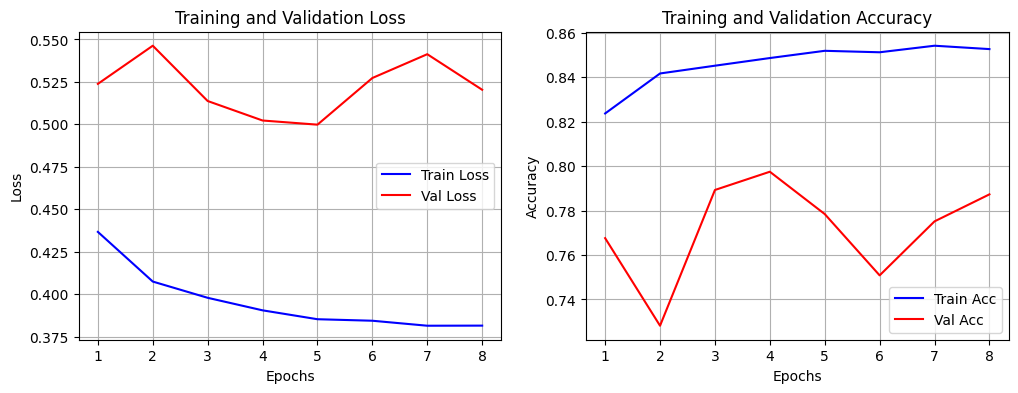

In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm import tqdm

# Настройка устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net.to(device)

# Веса классов и функция потерь
class_weights = torch.tensor([2.0, 8.0]).to(device) 
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
epochs = 20

# Инициализация Early Stopping (остановка, если val_loss не падает 3 эпохи подряд)
early_stopping = EarlyStopping(patience=3, min_delta=0.001)

# Списки для сохранения метрик и построения графиков
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
}

for epoch in range(epochs):
    #===== TRAIN =====
    net.train()
    total_loss = 0.0
    correct = 0
    total = 0
    
    for batch in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
        tokens = batch["tokens"].to(device)
        targets = batch["targets"].to(device)
        
        optimizer.zero_grad()
        outputs = net(tokens)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * tokens.size(0)
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == targets).sum().item()
        total += targets.size(0)
        
    epoch_loss = total_loss / total
    epoch_acc = correct / total
    
    history["train_loss"].append(epoch_loss)
    history["train_acc"].append(epoch_acc)
    
    # ===== VALIDATION =====
    net.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for batch in tqdm(val_dataloader, desc=f"Val {epoch+1}/{epochs}"):
            tokens = batch["tokens"].to(device)
            targets = batch["targets"].to(device)
            
            outputs = net(tokens)
            loss = criterion(outputs, targets)
            
            val_loss += loss.item() * tokens.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_correct += (predicted == targets).sum().item()
            val_total += targets.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total
    
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)
    
    print(
        f"Epoch {epoch+1}/{epochs} - "
        f"Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}"
    )
    
    # Проверка условия ранней остановки
    early_stopping(epoch_val_loss, net)
    if early_stopping.early_stop:
        print(f"Ранняя остановка активирована на эпохе {epoch+1}!")
        # Загружаем веса лучшей модели, сохраненные внутри EarlyStopping
        net.load_state_dict(early_stopping.best_model_wts)
        break

# ===== ПОСТРОЕНИЕ ГРАФИКОВ ====
epochs_range = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(12, 4))

# График Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], "b-", label="Train Loss")
plt.plot(epochs_range, history["val_loss"], "r-", label="Val Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# График Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], "b-", label="Train Acc")
plt.plot(epochs_range, history["val_acc"], "r-", label="Val Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
total_loss = 0.0
correct = 0
total = 0

# Для precision/recall
tp = 0  # true positives (предсказано 1, истинно 1)
fp = 0  # false positives (предсказано 1, истинно 0)
fn = 0  # false negatives (предсказано 0, истинно 1)

net.eval()

with torch.no_grad():
    for batch in test_dataloader:
        tokens = batch['tokens'].to(device)
        targets = batch['targets'].to(device)

        outputs = net(tokens)
        loss = criterion(outputs, targets)

        total_loss += loss.item() * tokens.size(0)

        _, predicted = torch.max(outputs, 1)

        correct += (predicted == targets).sum().item()
        total += targets.size(0)

        # Накопление для precision/recall
        tp += ((predicted == 1) & (targets == 1)).sum().item()
        fp += ((predicted == 1) & (targets == 0)).sum().item()
        fn += ((predicted == 0) & (targets == 1)).sum().item()

print(f"Test Loss: {total_loss / total:.4f}, Test Accuracy: {correct / total:.4f}")

# Расчёт precision/recall (с защитой от деления на ноль)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")

#20k 20k
#Test Loss: 7.2299, Test Accuracy: 0.7283
#Precision: 0.1175, Recall: 0.5784, F1: 0.1954

Test Loss: 0.5688, Test Accuracy: 0.6931
Precision: 0.0958, Recall: 0.5196, F1: 0.1618


Confusion Matrix:
[[1187  500]
 [  49   53]]


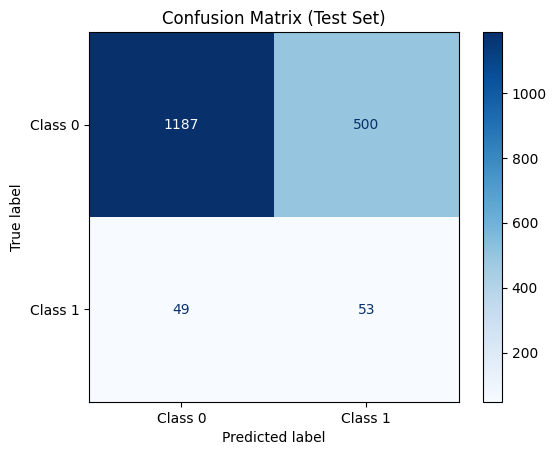

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

net.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_dataloader:
        tokens = batch['tokens'].to(device)
        targets = batch['targets'].to(device)

        outputs = net(tokens)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

# Строим confusion matrix
cm = confusion_matrix(all_targets, all_preds)

print("Confusion Matrix:")
print(cm)

# Визуализация
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()